<center><h1>Raza_MohammadHasnain_HW6_Extra</h1></center>
<br>
<center><font size="4">Extra Practice: ISLR 5.4.2, 6.8.4, 8.4.4 and 9.7.2</font></center>

**Name:** Mohammad Hasnain Raza  
**GitHub Username:** hasnainrazaa03  
**USC ID:** 1259246355

Package imports

In [1]:
# all imports and dependencies
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")

# seed used for the simulation in 5.4.2 (h)
SEED = 42

## 6.1. ISLR 5.4.2 - Extra Practice

*We will now derive the probability that a given observation is part of a bootstrap sample. Suppose that we obtain a bootstrap sample from a set of $n$ observations.*

**(a)** *What is the probability that the first bootstrap observation is not the $j$th observation from the original sample? Justify your answer.* **Answer.** Each bootstrap draw picks one of the $n$ observations uniformly at random, so it is the $j$th one with probability $1/n$ and **not the $j$th one with probability $1 - 1/n$**.

**(b)** *What is the probability that the second bootstrap observation is not the $j$th observation from the original sample?* **Answer.** The draws are made with replacement, so the second draw is again uniform over all $n$ observations and independent of the first. The probability is again **$1 - 1/n$**.

**(c)** *Argue that the probability that the $j$th observation is not in the bootstrap sample is $(1 - 1/n)^n$.* **Answer.** The $j$th observation is not in the bootstrap sample only if none of the $n$ draws picks it. The draws are independent and each misses it with probability $1 - 1/n$, so the probability is $(1 - 1/n) \times \cdots \times (1 - 1/n) = (1 - 1/n)^n$.

**(d)** *When $n = 5$, what is the probability that the $j$th observation is in the bootstrap sample?* **Answer.** $1 - (1 - 1/5)^5 = 1 - 0.8^5 = 1 - 0.32768 = \mathbf{0.6723}$.

**(e)** *When $n = 100$, what is the probability that the $j$th observation is in the bootstrap sample?* **Answer.** $1 - 0.99^{100} = 1 - 0.36603 = \mathbf{0.6340}$.

**(f)** *When $n = 10{,}000$, what is the probability that the $j$th observation is in the bootstrap sample?* **Answer.** $1 - 0.9999^{10000} = 1 - 0.36786 = \mathbf{0.6321}$.

In [2]:
for n in [5, 100, 10_000]:
    print(f"n = {n}: P(j-th observation in the bootstrap sample) = {1 - (1 - 1 / n) ** n:.5f}")
print(f"limit 1 - 1/e = {1 - np.exp(-1):.5f}")

n = 5: P(j-th observation in the bootstrap sample) = 0.67232
n = 100: P(j-th observation in the bootstrap sample) = 0.63397
n = 10000: P(j-th observation in the bootstrap sample) = 0.63214
limit 1 - 1/e = 0.63212


**(g)** *Create a plot that displays, for each integer value of $n$ from 1 to 100,000, the probability that the $j$th observation is in the bootstrap sample. Comment on what you observe.*

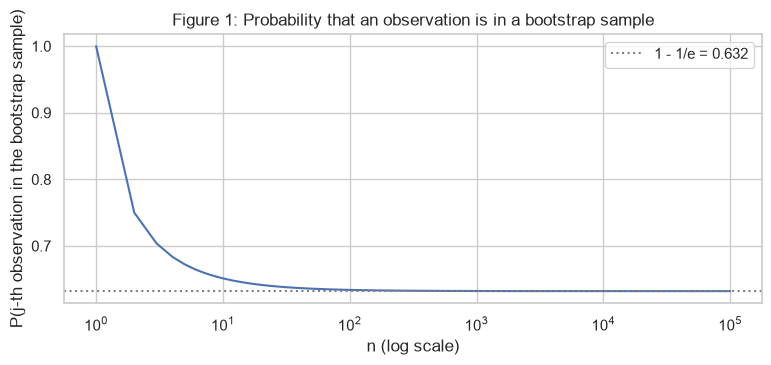

In [3]:
n_values = np.arange(1, 100_001)
in_sample = 1 - (1 - 1 / n_values) ** n_values

plt.figure(figsize=(9, 3.5))
plt.semilogx(n_values, in_sample)
plt.axhline(1 - np.exp(-1), color="gray", ls=":", label="1 - 1/e = 0.632")
plt.xlabel("n (log scale)")
plt.ylabel("P(j-th observation in the bootstrap sample)")
plt.title("Figure 1: Probability that an observation is in a bootstrap sample")
plt.legend()
plt.show()

**Answer.** The probability is 1 for $n = 1$, drops quickly (0.75 at $n = 2$, 0.67 at $n = 5$) and then levels off at about **0.632** for all $n$ above a few hundred. This is the limit $1 - \lim_{n\to\infty}(1 - 1/n)^n = 1 - e^{-1} \approx 0.632$. So a bootstrap sample contains about 63% of the distinct observations, and the other 37% are the out-of-bag observations used for the OOB error in part 1(c).

**(h)** *We will now investigate numerically the probability that a bootstrap sample of size $n = 100$ contains the $j$th observation. Here $j = 4$. We repeatedly create bootstrap samples, and each time we record whether or not the fourth observation is contained in the bootstrap sample. Comment on the results obtained.*

In [4]:
# 10000 bootstrap samples of size 100, does each one contain observation 4?
rng = np.random.default_rng(SEED)
contains_4 = [(rng.integers(1, 101, size=100) == 4).any() for _ in range(10_000)]
print(f"fraction of samples that contain observation 4: {np.mean(contains_4):.4f}, exact value: {1 - 0.99 ** 100:.4f}")

fraction of samples that contain observation 4: 0.6304, exact value: 0.6340


**Answer.** The simulated fraction is close to the exact value $1 - 0.99^{100} \approx 0.634$ from (e). The small difference is Monte Carlo error: with 10,000 repetitions the standard error is about $\sqrt{0.634 \times 0.366 / 10000} \approx 0.005$.

## 6.2. ISLR 6.8.4 - Extra Practice

*Suppose we estimate the regression coefficients in a linear regression model by minimizing*
$$\sum_{i=1}^n \Big(y_i - \beta_0 - \sum_{j=1}^p \beta_j x_{ij}\Big)^2 + \lambda \sum_{j=1}^p \beta_j^2$$
*for a particular value of $\lambda$. For parts (a) through (e), indicate which of i. through v. is correct (the same choices as in ISLR 6.6.3). Justify your answer.*

Here the direction is the opposite of 6.6.3: $\lambda = 0$ is least squares, and as $\lambda \to \infty$ all coefficients shrink to 0 and the model becomes the constant $\bar y$. So increasing $\lambda$ **decreases the flexibility**.

**(a)** *As we increase $\lambda$ from 0, the training RSS will:* **Answer. iii. Steadily increase.** At $\lambda = 0$ the training RSS is the smallest possible (least squares). A larger penalty pulls the coefficients further away from the least squares values, so the training RSS goes up, toward the RSS of the null model.

**(b)** *Repeat (a) for test RSS.* **Answer. ii. Decrease initially, and then eventually start increasing in a U shape.** A little shrinkage lowers the variance more than it adds bias, so the test RSS goes down at first. When $\lambda$ is large the coefficients are shrunk too much, the bias dominates and the test RSS goes back up.

**(c)** *Repeat (a) for variance.* **Answer. iv. Steadily decrease.** More shrinkage makes the fit less sensitive to the training sample, so the variance goes down, to 0 for the constant model in the limit.

**(d)** *Repeat (a) for (squared) bias.* **Answer. iii. Steadily increase.** At $\lambda = 0$ the bias is that of least squares (the lowest). Shrinking the coefficients toward 0 moves the fit away from the true function, so the squared bias goes up.

**(e)** *Repeat (a) for the irreducible error.* **Answer. v. Remain constant.** $\text{Var}(\varepsilon)$ does not depend on the model, so it does not change with $\lambda$.

## 6.3. ISLR 8.4.4 - Extra Practice

*This question relates to the plots in Figure 8.14 of ISLR.*

**(a)** *Sketch the tree corresponding to the partition of the predictor space illustrated in the left-hand panel of Figure 8.14. The numbers inside the boxes indicate the mean of $Y$ within each region.* **Answer.** The left-hand panel is first cut at $X_1 = 1$ (the region $X_1 \ge 1$ has mean 5). The part with $X_1 < 1$ is cut at $X_2 = 1$ (the top part has mean 15). The bottom-left part is cut at $X_1 = 0$ (the left piece has mean 3), and the piece with $0 \le X_1 < 1$ is cut at $X_2 = 0$ (mean 10 below and 0 above). The partition and the matching tree are drawn below. As in ISLR, the left branch of each split is the one where the condition is true.

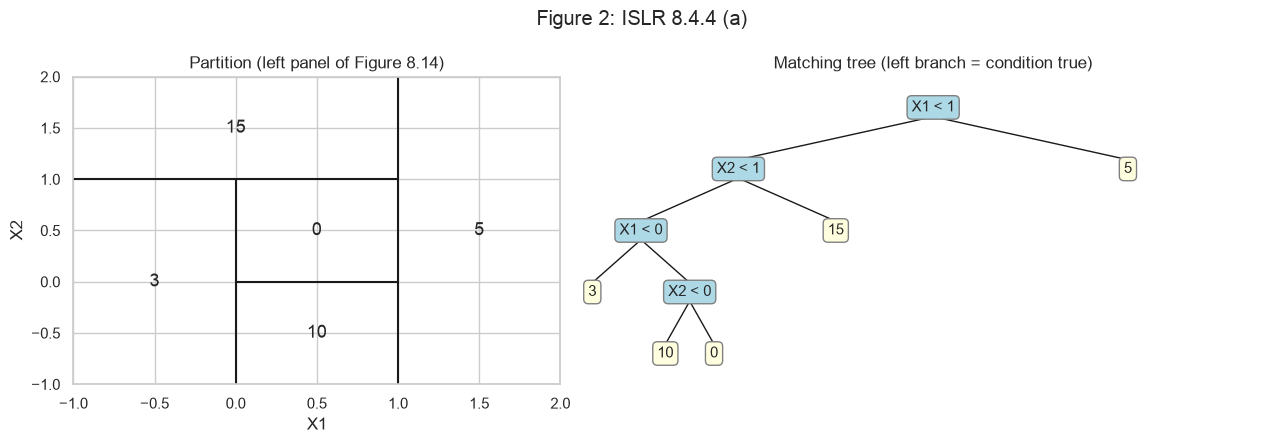

In [5]:
def draw_tree(ax, node, x, y, dx, dy=1.0):
    # a node is either a leaf value or a tuple (condition, left subtree, right subtree)
    if not isinstance(node, tuple):
        ax.text(x, y, f"{node}", ha="center", va="center", fontsize=11, bbox={"boxstyle": "round", "fc": "lightyellow", "ec": "gray"})
        return
    label, left, right = node
    ax.text(x, y, label, ha="center", va="center", fontsize=11, bbox={"boxstyle": "round", "fc": "lightblue", "ec": "gray"})
    for child, child_x in [(left, x - dx), (right, x + dx)]:
        ax.plot([x, child_x], [y - 0.15, y - dy + 0.15], "k-", lw=1)
        draw_tree(ax, child, child_x, y - dy, dx / 2, dy)


def draw_partition(ax, lines, regions, xlim, ylim):
    # lines are ((x0, x1), (y0, y1)) segments, regions are (x, y, mean) labels
    for xs, ys in lines:
        ax.plot(xs, ys, "k-")
    for x, y, value in regions:
        ax.text(x, y, f"{value}", ha="center", va="center", fontsize=13)
    ax.set(xlim=xlim, ylim=ylim, xlabel="X1", ylabel="X2")


LEFT_TREE = ("X1 < 1", ("X2 < 1", ("X1 < 0", 3, ("X2 < 0", 10, 0)), 15), 5)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
draw_partition(axes[0],
               lines=[((1, 1), (-1, 2)), ((-1, 1), (1, 1)), ((0, 0), (-1, 1)), ((0, 1), (0, 0))],
               regions=[(1.5, 0.5, 5), (0, 1.5, 15), (-0.5, 0, 3), (0.5, -0.5, 10), (0.5, 0.5, 0)],
               xlim=(-1, 2), ylim=(-1, 2))
axes[0].set_title("Partition (left panel of Figure 8.14)")
draw_tree(axes[1], LEFT_TREE, x=0, y=0, dx=2.0)
axes[1].set(xlim=(-3.5, 3.5), ylim=(-4.5, 0.5))
axes[1].axis("off")
axes[1].set_title("Matching tree (left branch = condition true)")
fig.suptitle("Figure 2: ISLR 8.4.4 (a)")
plt.tight_layout()
plt.show()

**(b)** *Create a diagram similar to the left-hand panel of Figure 8.14, using the tree illustrated in the right-hand panel of the same figure. You should divide up the predictor space into the correct regions, and indicate the mean for each region.* **Answer.** The tree in the right-hand panel splits on $X_2 < 1$ first. For $X_2 < 1$ it splits on $X_1 < 1$ (means $-1.80$ and $0.63$). For $X_2 \ge 1$ it splits on $X_2 < 2$: the region $X_2 \ge 2$ has mean $2.49$, and the strip $1 \le X_2 < 2$ is split at $X_1 < 0$ (means $-1.06$ and $0.21$). The five regions are:

| Region | Mean of $Y$ |
|---|---|
| $X_2 < 1$, $X_1 < 1$ | $-1.80$ |
| $X_2 < 1$, $X_1 \ge 1$ | $0.63$ |
| $1 \le X_2 < 2$, $X_1 < 0$ | $-1.06$ |
| $1 \le X_2 < 2$, $X_1 \ge 0$ | $0.21$ |
| $X_2 \ge 2$ | $2.49$ |

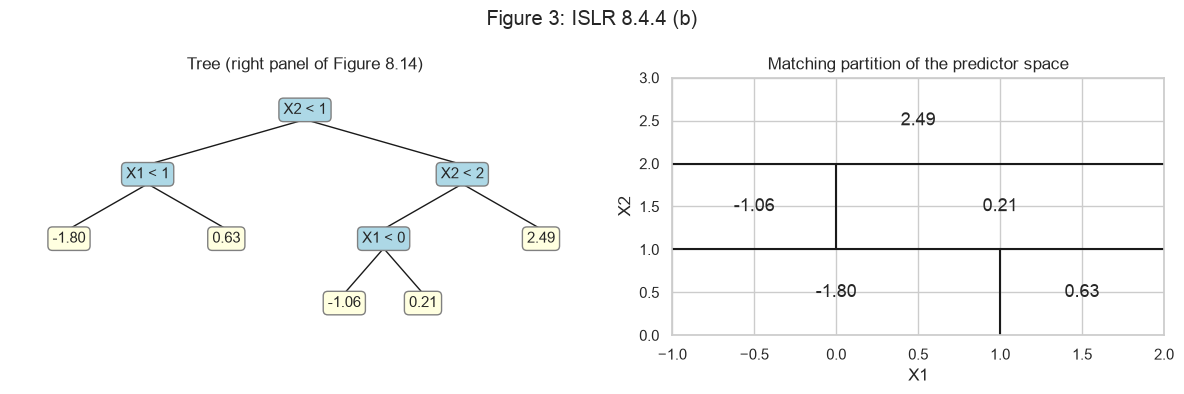

In [6]:
RIGHT_TREE = ("X2 < 1", ("X1 < 1", "-1.80", "0.63"), ("X2 < 2", ("X1 < 0", "-1.06", "0.21"), "2.49"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.2, 1]})
draw_tree(axes[0], RIGHT_TREE, x=0, y=0, dx=1.6)
axes[0].set(xlim=(-3, 3), ylim=(-3.5, 0.5))
axes[0].axis("off")
axes[0].set_title("Tree (right panel of Figure 8.14)")
draw_partition(axes[1],
               lines=[((-1, 2), (1, 1)), ((1, 1), (0, 1)), ((-1, 2), (2, 2)), ((0, 0), (1, 2))],
               regions=[(0, 0.5, "-1.80"), (1.5, 0.5, "0.63"), (-0.5, 1.5, "-1.06"), (1, 1.5, "0.21"), (0.5, 2.5, "2.49")],
               xlim=(-1, 2), ylim=(0, 3))
axes[1].set_title("Matching partition of the predictor space")
fig.suptitle("Figure 3: ISLR 8.4.4 (b)")
plt.tight_layout()
plt.show()

## 6.4. ISLR 9.7.2 - Extra Practice

*We have seen that in $p = 2$ dimensions, a linear decision boundary takes the form $\beta_0 + \beta_1 X_1 + \beta_2 X_2 = 0$. We now investigate a non-linear decision boundary.*

**(a)** *Sketch the curve $(1 + X_1)^2 + (2 - X_2)^2 = 4$.*

**(b)** *On your sketch, indicate the set of points for which $(1 + X_1)^2 + (2 - X_2)^2 > 4$, as well as the set of points for which $(1 + X_1)^2 + (2 - X_2)^2 \le 4$.* **Answer.** The curve is a **circle with center $(-1, 2)$ and radius 2**. The points with $(1 + X_1)^2 + (2 - X_2)^2 \le 4$ are the circle and its inside (shaded red in Figure 4), and the points with $> 4$ are everything outside the circle (blue).

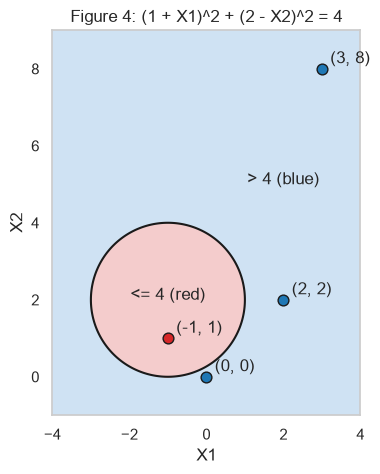

(0, 0): value = 5 -> blue
(-1, 1): value = 1 -> red
(2, 2): value = 9 -> blue
(3, 8): value = 52 -> blue


In [7]:
POINTS = np.array([[0, 0], [-1, 1], [2, 2], [3, 8]])


def circle_value(x1, x2):
    return (1 + x1) ** 2 + (2 - x2) ** 2


grid_x1, grid_x2 = np.meshgrid(np.linspace(-4, 4, 400), np.linspace(-1, 9, 400))
fig, ax = plt.subplots(figsize=(4.5, 5))
ax.contourf(grid_x1, grid_x2, circle_value(grid_x1, grid_x2) <= 4, levels=[-0.5, 0.5, 1.5], colors=["#cfe2f3", "#f4cccc"])
ax.contour(grid_x1, grid_x2, circle_value(grid_x1, grid_x2), levels=[4], colors="k")
for x1, x2 in POINTS:
    color = "tab:blue" if circle_value(x1, x2) > 4 else "tab:red"
    ax.scatter(x1, x2, c=color, s=60, edgecolors="k", zorder=3)
    ax.annotate(f"({x1}, {x2})", (x1, x2), textcoords="offset points", xytext=(6, 4))
ax.text(-1, 2, "<= 4 (red)", ha="center")
ax.text(2, 5, "> 4 (blue)", ha="center")
ax.set(xlabel="X1", ylabel="X2", aspect="equal", title="Figure 4: (1 + X1)^2 + (2 - X2)^2 = 4")
plt.show()

for x1, x2 in POINTS:
    print(f"({x1}, {x2}): value = {circle_value(x1, x2)} -> {'blue' if circle_value(x1, x2) > 4 else 'red'}")

**(c)** *Suppose that a classifier assigns an observation to the blue class if $(1 + X_1)^2 + (2 - X_2)^2 > 4$, and to the red class otherwise. To what class is the observation $(0, 0)$ classified? $(-1, 1)$? $(2, 2)$? $(3, 8)$?* **Answer.** The code above also checks these.

| Point | $(1 + X_1)^2 + (2 - X_2)^2$ | Class |
|---|---|---|
| $(0, 0)$ | $1 + 4 = 5 > 4$ | **Blue** |
| $(-1, 1)$ | $0 + 1 = 1 \le 4$ | **Red** |
| $(2, 2)$ | $9 + 0 = 9 > 4$ | **Blue** |
| $(3, 8)$ | $16 + 36 = 52 > 4$ | **Blue** |

**(d)** *Argue that while the decision boundary in (c) is not linear in terms of $X_1$ and $X_2$, it is linear in terms of $X_1$, $X_1^2$, $X_2$, and $X_2^2$.* **Answer.** Expanding the boundary,
$$(1 + X_1)^2 + (2 - X_2)^2 - 4 = 1 + 2X_1 + X_1^2 + 4 - 4X_2 + X_2^2 - 4 = 1 + 2X_1 + X_1^2 - 4X_2 + X_2^2.$$
So the boundary is $1 + 2X_1 + X_1^2 - 4X_2 + X_2^2 = 0$. In the original $(X_1, X_2)$ plane it is a circle, but in the enlarged feature space $(X_1, X_1^2, X_2, X_2^2)$ it is the hyperplane $\beta_0 + \beta_1 X_1 + \beta_2 X_1^2 + \beta_3 X_2 + \beta_4 X_2^2 = 0$ with $\beta = (1, 2, 1, -4, 1)$. This is the idea behind enlarging the feature space with polynomial terms (and behind kernels) for support vector classifiers.

### References

1. G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning* (ISLR), Ch. 5.2 (the bootstrap), Ch. 6.2 (ridge regression), Ch. 8.1 (decision trees) and Ch. 9.1 to 9.3 (hyperplanes and non-linear decision boundaries).